# Data Exploration — Complaint Escalation Risk

**Dataset source:** [Women's E-Commerce Clothing Reviews](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews) (Kaggle, `Womens Clothing E-Commerce Reviews.csv`)

This dataset stands in for the assignment's e-commerce complaint scenario: each row is a customer
review that combines **customer profile data** (age, department/division/class), **free text**
(review title + body), and a **satisfaction signal** (star rating, recommended flag) — the same
shape of inputs the hybrid system is meant to reason over (profile + complaint text + history).

It is used as a single source for **both** the Classical ML baseline (tabular + TF-IDF text)
and the RNN/LSTM component (review text sequences).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
df = df.drop(columns=["Unnamed: 0"])
df.head(3)

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses


## Dataset shape

In [2]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.dtypes

Rows: 23486, Columns: 10


Clothing ID                int64
Age                        int64
Title                        str
Review Text                  str
Rating                     int64
Recommended IND            int64
Positive Feedback Count    int64
Division Name                str
Department Name              str
Class Name                   str
dtype: object

## Target column

The raw dataset has no escalation-risk label, so we **derive** a 3-class `risk_level` target from
the star `Rating` (1-5), mirroring how a real complaints team would bucket dissatisfaction into
escalation risk.

**Caveat:** this is a PROXY. The data contains reviews, not complaints, and no escalation outcomes, so `risk_level` measures dissatisfaction, not observed escalation.


| Rating | risk_level | Rationale |
|---|---|---|
| 1-2 | high | Strongly negative experience (proxy for escalation / churn risk) |
| 3 | medium | Lukewarm / mixed experience -> needs a closer look |
| 4-5 | low | Positive experience (proxy for low escalation risk) |

This is the column every model (classical ML, RNN, and — in the hybrid step — CNN) is ultimately
trying to help predict.

In [3]:
def to_risk(rating):
    if rating <= 2:
        return "high"
    elif rating == 3:
        return "medium"
    else:
        return "low"

df["risk_level"] = df["Rating"].apply(to_risk)
df[["Rating", "Recommended IND", "risk_level"]].head(5)

,Rating,Recommended IND,risk_level
0,4,1,low
1,5,1,low
2,3,0,medium
3,5,1,low
4,5,1,low


## Feature columns

- **Tabular features** (-> Classical ML): `Age`, `Positive Feedback Count`, `Recommended IND`,
  `Division Name`, `Department Name`, `Class Name`
- **Text feature** (-> Classical ML TF-IDF *and* RNN/LSTM sequence input): `Review Text`
  (optionally concatenated with `Title`)
- **Target**: `risk_level` (derived above)

In [4]:
TABULAR_FEATURES = ["Age", "Positive Feedback Count", "Recommended IND",
                    "Division Name", "Department Name", "Class Name"]
TEXT_FEATURE = "Review Text"
TARGET = "risk_level"

print("Tabular features:", TABULAR_FEATURES)
print("Text feature:", TEXT_FEATURE)
print("Target:", TARGET)

Tabular features: ['Age', 'Positive Feedback Count', 'Recommended IND', 'Division Name', 'Department Name', 'Class Name']
Text feature: Review Text
Target: risk_level


## Missing values

In [5]:
missing = df.isna().sum()
print(missing[missing > 0])

Title              3810
Review Text         845
Division Name        14
Department Name      14
Class Name           14
dtype: int64


**Handling strategy:**
- `Review Text` missing (845 rows, ~3.6%): the text feature is required by both the classical TF-IDF
  pipeline and the RNN, so these rows are **dropped**.
- `Division Name` / `Department Name` / `Class Name` missing (14 rows each, <0.1%): filled with
  `"Unknown"` so the categorical encoders have a defined value rather than dropping more rows.
- `Title` is not used as a model feature, so its missing values are left as-is.

In [6]:
df_clean = df.dropna(subset=[TEXT_FEATURE]).copy()
for col in ["Division Name", "Department Name", "Class Name"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

print(f"Rows before cleaning: {len(df)}")
print(f"Rows after cleaning:  {len(df_clean)}")
assert df_clean[TABULAR_FEATURES + [TEXT_FEATURE, TARGET]].isna().sum().sum() == 0
print("No missing values remain in the selected feature/target columns.")

Rows before cleaning: 23486
Rows after cleaning:  22641
No missing values remain in the selected feature/target columns.


## Class distribution

risk_level
low       17448
medium     2823
high       2370
Name: count, dtype: int64
risk_level
low       77.1%
medium    12.5%
high      10.5%
Name: proportion, dtype: str


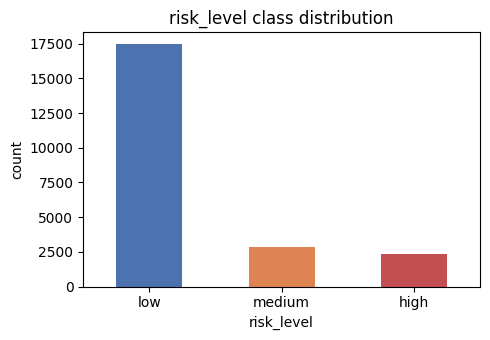

In [7]:
counts = df_clean[TARGET].value_counts().reindex(["low", "medium", "high"])
props = df_clean[TARGET].value_counts(normalize=True).reindex(["low", "medium", "high"])
print(counts)
print((props * 100).round(1).astype(str) + "%")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts.plot(kind="bar", color=["#4C72B0", "#DD8452", "#C44E52"], ax=ax)
ax.set_title("risk_level class distribution")
ax.set_xlabel("risk_level")
ax.set_ylabel("count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The classes are **imbalanced** (roughly 78% low / 12% medium / 10% high), which mirrors a real
complaints stream where most interactions are routine and only a minority escalate. This is
important context for evaluation later: plain accuracy will look high by always predicting
`low`, so F1 (macro / per-class) is the more meaningful metric, and the split below is
**stratified** so all three sets keep this same proportion.

## Train / Validation / Test split (70 / 15 / 15)

To **avoid data leakage**:
- The split is performed **once, here**, before any vectorizer / scaler / model is fit.
- `TfidfVectorizer`, `TextVectorization`, scalers and encoders used by the later training scripts
  must be `fit` only on the **train** split and then applied (`transform`) to validation/test —
  never fit on the full dataset.
- The split is **stratified** on `risk_level` so the class balance is preserved across all three
  sets, and a fixed `random_state` keeps it reproducible.
- The resulting `train.csv`, `val.csv`, `test.csv` files are saved so that
  `train_classical_model.py`, `train_cnn_model.py`, `train_rnn_model.py` and `hybrid_inference.py`
  all train/evaluate on **exactly the same rows** — a different split per script would itself be a
  leakage / inconsistency risk.

In [8]:
# 70% train, 15% val, 15% test — stratified on the target
train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean[TARGET], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=RANDOM_STATE
)

for name, split in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    pct = len(split) / len(df_clean) * 100
    print(f"{name:10s}: {len(split):5d} rows ({pct:.1f}%)")
    print("   ", split[TARGET].value_counts(normalize=True).reindex(["low","medium","high"]).round(3).to_dict())

train     : 15848 rows (70.0%)
    {'low': 0.771, 'medium': 0.125, 'high': 0.105}
validation:  3396 rows (15.0%)
    {'low': 0.771, 'medium': 0.125, 'high': 0.105}
test      :  3397 rows (15.0%)
    {'low': 0.771, 'medium': 0.125, 'high': 0.105}


In [9]:
train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)
print("Saved train.csv, val.csv, test.csv")

Saved train.csv, val.csv, test.csv


## Summary

- **Source**: Women's E-Commerce Clothing Reviews (Kaggle), 23,486 rows, 11 columns
- **Target**: `risk_level` (low/medium/high) derived from `Rating`
- **Features**: 6 tabular columns + `Review Text` (used by both Classical ML and RNN)
- **Cleaning**: dropped 845 rows missing review text; filled 14 rows of missing category fields with "Unknown"
- **Split**: stratified 70/15/15 -> `train.csv` / `val.csv` / `test.csv`, reused by every downstream
  training script to prevent leakage and keep evaluation comparable across components